[![Open In Colab](https://colab.research.google.com/assets/colab-badge.svg)](https://colab.research.google.com/github/dandi/example-notebooks/blob/master/001259/SchneiderLab/opto_example_notebook.ipynb)

## Installing requirements

The cell below installs every Python package needed to run this notebook, at fully pinned versions, using [`uv`](https://github.com/astral-sh/uv) for fast resolution. In Colab the cell is collapsed by default — click the ▶ button to run it.

In [ ]:
#@title Installing requirements (click ▶ to run) { display-mode: "form" }
# Colab provides Python 3.13. We install with `uv --system` because Colab's
# kernel runs outside a virtualenv. All versions (direct + transitive) are
# pinned below so the notebook is reproducible regardless of resolver drift.
!pip install -q uv
!uv pip install --system \
    "acres==0.5.0" \
    "aiohappyeyeballs==2.7.1" \
    "aiohttp==3.14.3" \
    "aiosignal==1.4.0" \
    "annotated-types==0.8.0" \
    "arrow==1.4.0" \
    "attrs==26.1.0" \
    "bids-validator-deno==3.0.2" \
    "bidsschematools==1.2.7" \
    "blessed==1.50.0" \
    "certifi==2026.7.22" \
    "cffi==2.1.1" \
    "charset-normalizer==3.4.9" \
    "ci-info==0.4.0" \
    "click==8.5.0" \
    "click-didyoumean==0.3.1" \
    "cloudpickle==3.1.2" \
    "contourpy==1.3.3" \
    "cryptography==50.0.1" \
    "cycler==0.12.1" \
    "dandi==0.83.0" \
    "dandischema==0.14.0" \
    "deno==2.9.8" \
    "dnspython==2.9.2" \
    "donfig==0.8.1.post1" \
    "email-validator==2.4.0" \
    "etelemetry==0.3.1" \
    "fasteners==0.20" \
    "fonttools==4.64.0" \
    "fqdn==1.5.1" \
    "frozenlist==1.8.0" \
    "fscacher==0.5.0" \
    "fsspec==2025.12.0" \
    "google-crc32c==1.8.0" \
    "h5py==3.16.0" \
    "hdmf==6.2.0" \
    "humanize==4.16.0" \
    "idna==3.19" \
    "interleave==0.3.0" \
    "isodate==0.7.2" \
    "isoduration==20.11.0" \
    "jaraco-classes==3.4.0" \
    "jaraco-context==6.1.2" \
    "jaraco-functools==4.6.0" \
    "jeepney==0.9.0" \
    "jinxed==2.1.1" \
    "joblib==1.6.0" \
    "jsonpointer==3.1.1" \
    "jsonschema==4.26.0" \
    "jsonschema-specifications==2025.9.1" \
    "keyring==25.7.0" \
    "keyrings-alt==5.0.2" \
    "kiwisolver==1.5.1" \
    "matplotlib==3.10.0" \
    "ml-dtypes==0.6.0" \
    "more-itertools==10.8.0" \
    "msgspec==0.22.0" \
    "multidict==6.7.1" \
    "natsort==8.4.0" \
    "numcodecs==0.17.1" \
    "numpy==2.1.3" \
    "nwbinspector==0.7.2" \
    "packaging==26.3" \
    "pandas==2.2.3" \
    "pillow==11.3.0" \
    "platformdirs==4.11.7" \
    "propcache==0.5.2" \
    "pycparser==3.0" \
    "pycryptodomex==3.23.0" \
    "pydantic==2.13.5" \
    "pydantic-core==2.46.5" \
    "pydantic-settings==2.16.3" \
    "pynwb==4.2.0" \
    "pyout==0.8.1" \
    "pyparsing==3.3.2" \
    "python-dateutil==2.9.0.post0" \
    "python-dotenv==1.2.3" \
    "pytz==2025.2" \
    "pyyaml==6.0.3" \
    "referencing==0.37.0" \
    "remfile==0.1.17" \
    "requests==2.32.4" \
    "rfc3339-validator==0.1.4" \
    "rfc3987==1.3.8" \
    "rpds-py==2026.6.3" \
    "ruamel-yaml==0.19.1" \
    "secretstorage==3.5.0" \
    "semantic-version==2.10.0" \
    "six==1.17.0" \
    "tenacity==9.1.4" \
    "tensorstore==0.1.85" \
    "tqdm==4.67.3" \
    "typing-extensions==4.16.0" \
    "typing-inspection==0.4.4" \
    "tzdata==2026.3" \
    "uri-template==1.3.0" \
    "urllib3==2.5.0" \
    "wcwidth==0.8.3" \
    "webcolors==25.10.0" \
    "yarl==1.24.5" \
    "zarr==3.4.2" \
    "zarr-checksum==0.4.7"
!curl -sL -o stream_nwbfile.py https://raw.githubusercontent.com/dandi/example-notebooks/master/001259/SchneiderLab/stream_nwbfile.py

> **⚠️ Restart runtime after install**
>
> The install may upgrade packages already loaded in the kernel. Go to **Runtime → Restart session**, then **Run all cells below** (skip this install cell on re-run).

# Opto Example Session

In [2]:
from stream_nwbfile import stream_nwbfile
import numpy as np
import matplotlib.pyplot as plt

This notebook showcases one example session from the 001259 dataset containing operant behavior and concurrent optogenetic stimulation.

In [3]:
DANDISET_ID = '001259'
DANDISET_VERSION = "0.261013.2200"
file_path = 'sub-m53/sub-m53_ses-231013_behavior+image+ogen.nwb'
nwbfile, io = stream_nwbfile(DANDISET_ID, file_path, DANDISET_VERSION)
display(nwbfile)

Data type,uint8
Shape,"(0, 0, 0)"
Array size,0.00 bytes
Chunk shape,None
Compression,None
Compression opts,None
Uncompressed size (bytes),0
Compressed size (bytes),0
Compression ratio,undefined
Data type,float64
Shape,"(17994,)"


Retrieve Opto and Behavioral data

In [4]:
# Opto
opto_stim_timestamps = np.asarray(nwbfile.stimulus["optogenetic_series"].timestamps)
opto_stim_data = np.asarray(nwbfile.stimulus["optogenetic_series"].data)
stim_power = 0.020
opto_onset_times = opto_stim_timestamps[opto_stim_data == stim_power]
opto_offset_times = opto_stim_timestamps[opto_stim_data == 0]

# Behavioral Events
tone_in = np.asarray(nwbfile.processing["behavior"].data_interfaces["toneIN"].timestamps)
tone_out = np.asarray(nwbfile.processing["behavior"].data_interfaces["toneOUT"].timestamps)
target_out = np.asarray(nwbfile.processing["behavior"].data_interfaces["targetOUT"].timestamps)
valve = np.asarray(nwbfile.processing["behavior"].data_interfaces["valve"].timestamps)

# Behavioral Time Series
encoder_data = np.asarray(nwbfile.processing["behavior"].data_interfaces["behavioral_time_series"]["encoder"].data)
encoder_timestamps = np.asarray(nwbfile.processing["behavior"].data_interfaces["behavioral_time_series"]["encoder"].timestamps)
lick_data = np.asarray(nwbfile.processing["behavior"].data_interfaces["behavioral_time_series"]["lick"].data)
lick_timestamps = np.asarray(nwbfile.processing["behavior"].data_interfaces["behavioral_time_series"]["lick"].timestamps)

# Behavioral Trials
trials = nwbfile.trials.to_dataframe()
trials = trials[trials.opto_trial]
example_rewarded_trial = trials[trials["rewarded"] == True].iloc[0]
example_unrewarded_trial = trials[trials["rewarded"] == False].iloc[0]

Plot an example rewarded trial

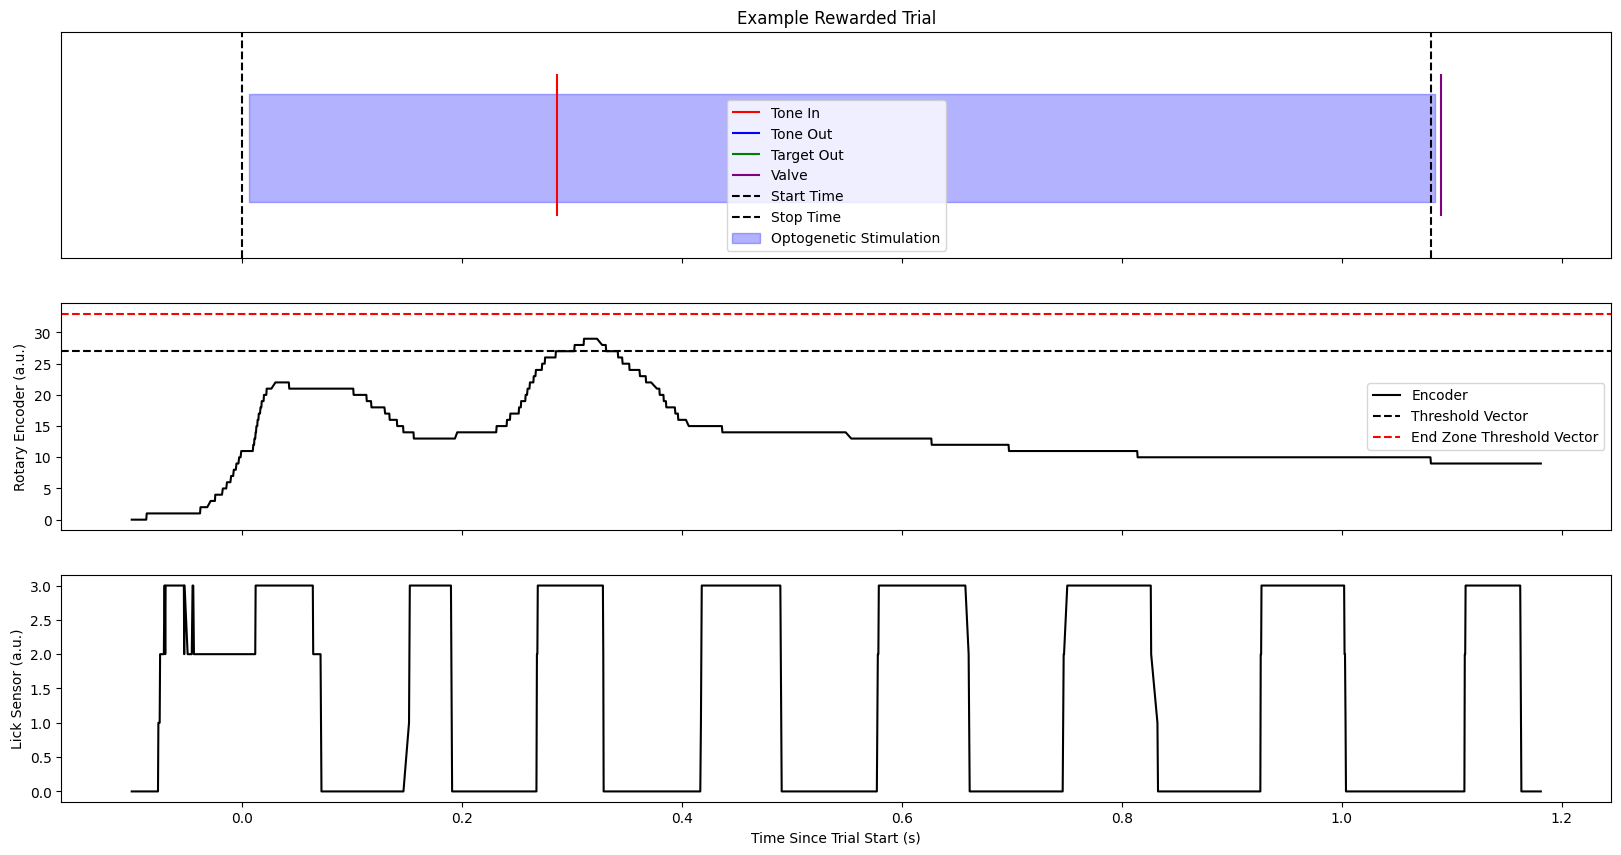

In [5]:
example_trial = example_rewarded_trial

# Define plot parameters
lineoffsets = 0
linelengths = 2.5
ylim = [-2, 2]
grace_time = 0.100
y = np.arange(-1, 1, 0.1)
alpha = 0.3

# Define time windows for plotting
plot_start_time = example_trial["start_time"] - grace_time
plot_end_time = example_trial["stop_time"] + grace_time
opto_onset_mask = (opto_onset_times >= plot_start_time) & (opto_onset_times <= plot_end_time)
opto_offset_mask = (opto_offset_times >= plot_start_time) & (opto_offset_times <= plot_end_time)
tone_in_mask = (tone_in >= plot_start_time) & (tone_in <= plot_end_time)
tone_out_mask = (tone_out >= plot_start_time) & (tone_out <= plot_end_time)
target_out_mask = (target_out >= plot_start_time) & (target_out <= plot_end_time)
valve_mask = (valve >= plot_start_time) & (valve <= plot_end_time)
encoder_mask = (encoder_timestamps >= plot_start_time) & (encoder_timestamps <= plot_end_time)
lick_mask = (lick_timestamps >= plot_start_time) & (lick_timestamps <= plot_end_time)

# Normalize times to trial start time
trial_start_time = example_trial["start_time"]
normalized_opto_onset_times = opto_onset_times[opto_onset_mask] - trial_start_time
normalized_opto_offset_times = opto_offset_times[opto_offset_mask] - trial_start_time
normalized_tone_in = tone_in[tone_in_mask] - trial_start_time
normalized_tone_out = tone_out[tone_out_mask] - trial_start_time
normalized_target_out = target_out[target_out_mask] - trial_start_time
normalized_valve = valve[valve_mask] - trial_start_time
normalized_encoder_timestamps = encoder_timestamps[encoder_mask] - trial_start_time
normalized_lick_timestamps = lick_timestamps[lick_mask] - trial_start_time

fig, axs = plt.subplots(3, 1, figsize=(20, 10), sharex=True)
axs[0].set_title("Example Rewarded Trial")
axs[0].eventplot(normalized_tone_in, color="red", label="Tone In", lineoffsets=lineoffsets, linelengths=linelengths)
axs[0].eventplot(normalized_tone_out, color="blue", label="Tone Out", lineoffsets=lineoffsets, linelengths=linelengths)
axs[0].eventplot(normalized_target_out, color="green", label="Target Out", lineoffsets=lineoffsets, linelengths=linelengths)
axs[0].eventplot(normalized_valve, color="purple", label="Valve", lineoffsets=lineoffsets, linelengths=linelengths)
axs[0].axvline(0, color="black", linestyle="--", label="Start Time")
axs[0].axvline(example_trial["stop_time"] - example_trial["start_time"], color="black", linestyle="--", label="Stop Time")
for i, (onset_time, offset_time) in enumerate(zip(normalized_opto_onset_times, normalized_opto_offset_times)):
    x1 = onset_time * np.ones(len(y))
    x2 = offset_time * np.ones(len(y))
    if i == 0:
        axs[0].fill_betweenx(y, x1, x2, color="blue", alpha=alpha, label="Optogenetic Stimulation")
    else:
        axs[0].fill_betweenx(y, x1, x2, color="blue", alpha=alpha)

axs[0].set_ylim(ylim)
axs[0].set_yticks([])
axs[0].legend()

axs[1].plot(normalized_encoder_timestamps, encoder_data[encoder_mask], color="k", label="Encoder")
axs[1].axhline(example_trial["ThresholdVector"], color="black", linestyle="--", label="Threshold Vector")
axs[1].axhline(example_trial["endZone_ThresholdVector"], color="red", linestyle="--", label="End Zone Threshold Vector")
axs[1].set_ylabel("Rotary Encoder (a.u.)")
axs[1].legend()

axs[2].plot(normalized_lick_timestamps, lick_data[lick_mask], color="k", label="Lick")
axs[2].set_ylabel("Lick Sensor (a.u.)")
_ = axs[2].set_xlabel("Time Since Trial Start (s)")

Plot an example unrewarded trial

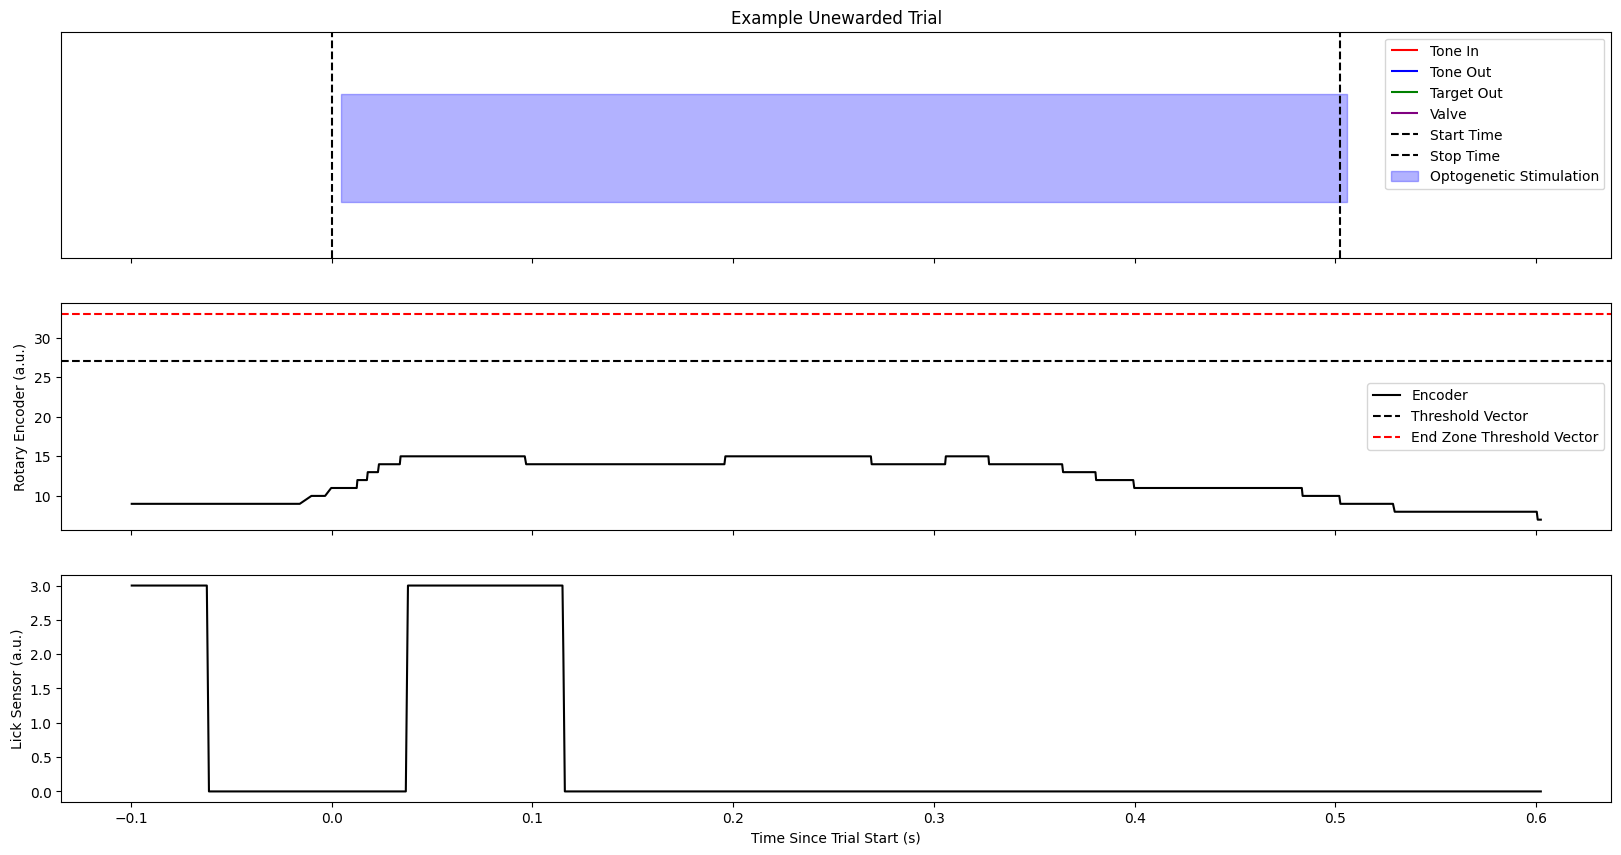

In [6]:
example_trial = example_unrewarded_trial

# Define plot parameters
lineoffsets = 0
linelengths = 2.5
ylim = [-2, 2]
grace_time = 0.100
y = np.arange(-1, 1, 0.1)
alpha = 0.3

# Define time windows for plotting
plot_start_time = example_trial["start_time"] - grace_time
plot_end_time = example_trial["stop_time"] + grace_time
opto_onset_mask = (opto_onset_times >= plot_start_time) & (opto_onset_times <= plot_end_time)
opto_offset_mask = (opto_offset_times >= plot_start_time) & (opto_offset_times <= plot_end_time)
tone_in_mask = (tone_in >= plot_start_time) & (tone_in <= plot_end_time)
tone_out_mask = (tone_out >= plot_start_time) & (tone_out <= plot_end_time)
target_out_mask = (target_out >= plot_start_time) & (target_out <= plot_end_time)
valve_mask = (valve >= plot_start_time) & (valve <= plot_end_time)
encoder_mask = (encoder_timestamps >= plot_start_time) & (encoder_timestamps <= plot_end_time)
lick_mask = (lick_timestamps >= plot_start_time) & (lick_timestamps <= plot_end_time)

# Normalize times to trial start time
trial_start_time = example_trial["start_time"]
normalized_opto_onset_times = opto_onset_times[opto_onset_mask] - trial_start_time
normalized_opto_offset_times = opto_offset_times[opto_offset_mask] - trial_start_time
normalized_tone_in = tone_in[tone_in_mask] - trial_start_time
normalized_tone_out = tone_out[tone_out_mask] - trial_start_time
normalized_target_out = target_out[target_out_mask] - trial_start_time
normalized_valve = valve[valve_mask] - trial_start_time
normalized_encoder_timestamps = encoder_timestamps[encoder_mask] - trial_start_time
normalized_lick_timestamps = lick_timestamps[lick_mask] - trial_start_time

fig, axs = plt.subplots(3, 1, figsize=(20, 10), sharex=True)
axs[0].set_title("Example Unewarded Trial")
axs[0].eventplot(normalized_tone_in, color="red", label="Tone In", lineoffsets=lineoffsets, linelengths=linelengths)
axs[0].eventplot(normalized_tone_out, color="blue", label="Tone Out", lineoffsets=lineoffsets, linelengths=linelengths)
axs[0].eventplot(normalized_target_out, color="green", label="Target Out", lineoffsets=lineoffsets, linelengths=linelengths)
axs[0].eventplot(normalized_valve, color="purple", label="Valve", lineoffsets=lineoffsets, linelengths=linelengths)
axs[0].axvline(0, color="black", linestyle="--", label="Start Time")
axs[0].axvline(example_trial["stop_time"] - example_trial["start_time"], color="black", linestyle="--", label="Stop Time")
for i, (onset_time, offset_time) in enumerate(zip(normalized_opto_onset_times, normalized_opto_offset_times)):
    x1 = onset_time * np.ones(len(y))
    x2 = offset_time * np.ones(len(y))
    if i == 0:
        axs[0].fill_betweenx(y, x1, x2, color="blue", alpha=alpha, label="Optogenetic Stimulation")
    else:
        axs[0].fill_betweenx(y, x1, x2, color="blue", alpha=alpha)

axs[0].set_ylim(ylim)
axs[0].set_yticks([])
axs[0].legend()

axs[1].plot(normalized_encoder_timestamps, encoder_data[encoder_mask], color="k", label="Encoder")
axs[1].axhline(example_trial["ThresholdVector"], color="black", linestyle="--", label="Threshold Vector")
axs[1].axhline(example_trial["endZone_ThresholdVector"], color="red", linestyle="--", label="End Zone Threshold Vector")
axs[1].set_ylabel("Rotary Encoder (a.u.)")
axs[1].legend()

axs[2].plot(normalized_lick_timestamps, lick_data[lick_mask], color="k", label="Lick")
axs[2].set_ylabel("Lick Sensor (a.u.)")
_ = axs[2].set_xlabel("Time Since Trial Start (s)")

In [7]:
io.close()